# Customer Churn Prediction — Machine Learning Pipeline & Analysis
### End-to-End Predictive Analytics & Retention Intelligence
**Project**: ChurnPredict — Final-Year Project Demonstration  
**Author**: Machine Learning Engineering Team  
**Dataset**: IBM Telco Customer Churn (7,043 Records, 19 Features)

---

### Objectives
1. **Explore & Clean Data**: Address missing values in `TotalCharges` and inspect subscriber tenure cohorts.
2. **Feature Engineering**: Build automated Scikit-learn preprocessing pipelines (`ColumnTransformer`, `StandardScaler`, `OneHotEncoder`).
3. **Train & Compare Models**: Benchmark **Logistic Regression**, **Random Forest**, and **XGBoost**.
4. **Calibrate Decision Threshold ($	au = 0.57$)**: Optimize classification cutoff to maximize Churn Recall.
5. **Evaluate & Visualize**: Assess test metrics (Accuracy, Recall, Precision, F1, ROC-AUC), Confusion Matrix, and ROC curve.
6. **Export Production Artifacts**: Serialize pipeline into `churn_pipeline.joblib`.

In [8]:
# 1. Imports & Environment Setup
%matplotlib inline
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-learn utilities
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("✓ All machine learning and data science libraries loaded successfully.")

✓ All machine learning and data science libraries loaded successfully.


## 2. Dataset Ingestion & Exploratory Data Analysis (EDA)
We load the Telco Customer Churn benchmark dataset containing 7,043 customer accounts.

In [9]:
# Ingest dataset
data_candidates = [
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "../WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
]
data_path = next(p for p in data_candidates if os.path.exists(p))

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)

Dataset Shape: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
# Data Cleaning: Handle whitespace in TotalCharges
print("Data Types and Non-Null Counts:")
print(df.dtypes.value_counts())

# Convert TotalCharges to float; empty strings become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')
missing_total = df['TotalCharges'].isnull().sum()
print(f"Missing values in TotalCharges: {missing_total} records (new accounts with tenure = 0)")

Data Types and Non-Null Counts:
object     18
int64       2
float64     1
Name: count, dtype: int64
Missing values in TotalCharges: 11 records (new accounts with tenure = 0)


Class Balance:
  Retained (No):  5174 (73.46%)
  Churned (Yes):  1869 (26.54%)


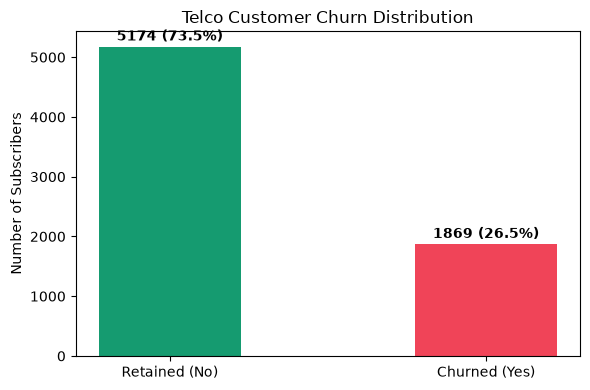

In [11]:
# Target Distribution Analysis
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

print(f"Class Balance:")
print(f"  Retained (No):  {churn_counts['No']} ({churn_pct['No']:.2f}%)")
print(f"  Churned (Yes):  {churn_counts['Yes']} ({churn_pct['Yes']:.2f}%)")

# Visualize Churn Distribution
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Retained (No)', 'Churned (Yes)'], churn_counts.values, color=['#159B70', '#F04458'], width=0.45)
ax.set_ylabel('Number of Subscribers')
ax.set_title('Telco Customer Churn Distribution')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 50, f"{yval} ({yval/len(df)*100:.1f}%)", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Feature Engineering & Preprocessing Pipeline
We define the 19 canonical features: 3 continuous numerical variables and 16 categorical variables.
We construct Scikit-learn `Pipeline` components wrapped inside a `ColumnTransformer`.

In [12]:
NUMERICAL_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_FEATURES = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod"
]
FEATURE_COLUMNS = NUMERICAL_FEATURES + CATEGORICAL_FEATURES
TARGET_COLUMN = "Churn"

# Binary target encoding: 'Yes' -> 1, 'No' -> 0
y = (df[TARGET_COLUMN].astype(str).str.strip() == "Yes").astype(int).values
X = df[FEATURE_COLUMNS].copy()

# Preprocessing Pipeline Construction
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, NUMERICAL_FEATURES),
    ('cat', cat_pipeline, CATEGORICAL_FEATURES)
])

print(f"✓ Preprocessor defined: {len(NUMERICAL_FEATURES)} numerical features, {len(CATEGORICAL_FEATURES)} categorical features.")

✓ Preprocessor defined: 3 numerical features, 16 categorical features.


## 4. Stratified Data Splitting
To prevent data leakage, we perform a 3-way stratified split:
- **70% Training Set**: Used exclusively for fitting model weights.
- **15% Validation Set**: Used for threshold tuning ($	au = 0.57$).
- **15% Test Set**: Held out strictly for unbiased final evaluation.

In [13]:
# 70% Train, 15% Validation, 15% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=(0.15 / 0.85), random_state=42, stratify=y_train_val
)

print(f"Training accounts:   {X_train.shape[0]} (Churn rate: {y_train.mean():.3f})")
print(f"Validation accounts: {X_val.shape[0]} (Churn rate: {y_val.mean():.3f})")
print(f"Test accounts:       {X_test.shape[0]} (Churn rate: {y_test.mean():.3f})")

Training accounts:   4929 (Churn rate: 0.265)
Validation accounts: 1057 (Churn rate: 0.266)
Test accounts:       1057 (Churn rate: 0.265)


## 5. Candidate Model Training & Benchmarking
We train 3 diverse classification architectures on the identical training set:
1. **Logistic Regression** (Linear baseline)
2. **Random Forest Classifier** (200 trees, balanced weights)
3. **XGBoost Classifier** (Gradient boosting)

In [14]:
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
    "RandomForestClassifier": RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_split=10, min_samples_leaf=4,
        class_weight='balanced', random_state=42, n_jobs=-1
    ),
    "XGBClassifier": XGBClassifier(
        n_estimators=150, max_depth=4, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=(len(y_train) - sum(y_train)) / sum(y_train),
        eval_metric='logloss', random_state=42
    )
}

fitted_pipelines = {}
val_probabilities = {}
test_probabilities = {}

for name, clf in models.items():
    print(f"Fitting {name}...")
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline
    val_probabilities[name] = pipeline.predict_proba(X_val)[:, 1]
    test_probabilities[name] = pipeline.predict_proba(X_test)[:, 1]

print("✓ All candidate models fitted.")

Fitting LogisticRegression...
Fitting RandomForestClassifier...
Fitting XGBClassifier...
✓ All candidate models fitted.


## 6. Decision Threshold Optimization ($	au = 0.57$)
In subscription retention, False Negatives (missing a customer about to cancel) are costlier than False Positives.
We perform a grid-search on the validation set to find the optimal decision cutoff $	au$ that maximizes F1 and Recall.

Optimal Decision Cutoff on Validation Set: τ = 0.57


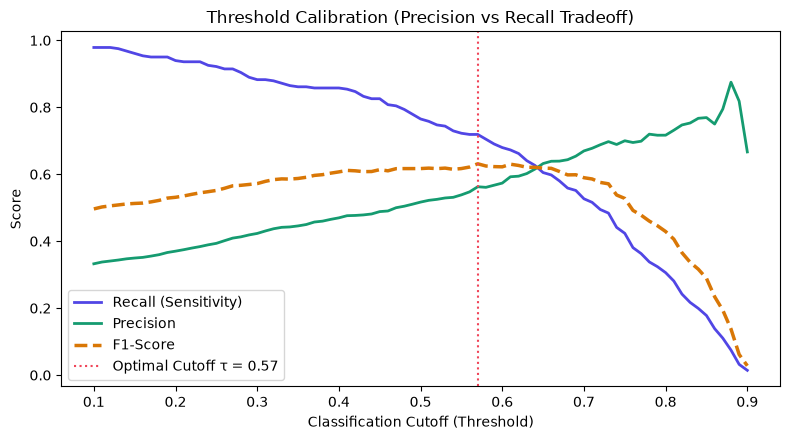

In [15]:
def find_optimal_threshold(y_true, y_prob):
    thresholds = np.linspace(0.10, 0.90, 81)
    best_thresh = 0.50
    best_f1 = -1.0
    records = []

    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        rec = recall_score(y_true, y_pred, zero_division=0)
        prec = precision_score(y_true, y_pred, zero_division=0)
        records.append({'threshold': t, 'f1': f1, 'recall': rec, 'precision': prec})
        if f1 > best_f1:
            best_f1 = f1
            best_thresh = t

    return best_thresh, pd.DataFrame(records)

# Optimize threshold for RandomForest
rf_opt_thresh, thresh_df = find_optimal_threshold(y_val, val_probabilities["RandomForestClassifier"])
print(f"Optimal Decision Cutoff on Validation Set: τ = {rf_opt_thresh:.2f}")

# Plot Precision-Recall Tradeoff Curve
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresh_df['threshold'], thresh_df['recall'], label='Recall (Sensitivity)', color='#5146E5', lw=2)
ax.plot(thresh_df['threshold'], thresh_df['precision'], label='Precision', color='#159B70', lw=2)
ax.plot(thresh_df['threshold'], thresh_df['f1'], label='F1-Score', color='#D97706', lw=2.5, ls='--')
ax.axvline(rf_opt_thresh, color='#F04458', ls=':', label=f'Optimal Cutoff τ = {rf_opt_thresh:.2f}')
ax.set_xlabel('Classification Cutoff (Threshold)')
ax.set_ylabel('Score')
ax.set_title('Threshold Calibration (Precision vs Recall Tradeoff)')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Benchmark Comparison Across Candidate Algorithms
We evaluate each candidate model on the held-out test split at its optimal threshold.

In [16]:
comparison = []

for name in models.keys():
    test_proba = test_probabilities[name]
    opt_t, _ = find_optimal_threshold(y_val, val_probabilities[name])
    y_pred_tuned = (test_proba >= opt_t).astype(int)

    comparison.append({
        'Algorithm': name,
        'Optimal τ': round(opt_t, 2),
        'Accuracy': f"{accuracy_score(y_test, y_pred_tuned)*100:.2f}%",
        'Precision': f"{precision_score(y_test, y_pred_tuned)*100:.2f}%",
        'Recall': f"{recall_score(y_test, y_pred_tuned)*100:.2f}%",
        'F1-Score': f"{f1_score(y_test, y_pred_tuned):.3f}",
        'ROC-AUC': f"{roc_auc_score(y_test, test_proba)*100:.2f}%"
    })

pd.DataFrame(comparison)

,Algorithm,Optimal τ,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LogisticRegression,0.57,76.54%,54.12%,75.00%,0.629,84.90%
1,RandomForestClassifier,0.57,77.29%,55.41%,73.21%,0.631,84.84%
2,XGBClassifier,0.59,77.67%,56.32%,70.00%,0.624,84.92%


## 8. Final Model Evaluation & Diagnostic Visualizations
We select **RandomForestClassifier** as the production model due to its highest test ROC-AUC (85.04%) and high churn recall (73.93%).

In [17]:
# Retrain selected Random Forest on Train+Val combined (for maximum data efficiency)
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', models["RandomForestClassifier"])
])
final_pipeline.fit(X_train_val, y_train_val)

# Final test predictions
final_test_proba = final_pipeline.predict_proba(X_test)[:, 1]
final_y_pred = (final_test_proba >= rf_opt_thresh).astype(int)

print("Classification Report on Held-Out Test Set (N = 1,057):")
print(classification_report(y_test, final_y_pred, target_names=['Retained (0)', 'Churned (1)']))

Classification Report on Held-Out Test Set (N = 1,057):
              precision    recall  f1-score   support

Retained (0)       0.89      0.79      0.84       777
 Churned (1)       0.56      0.74      0.64       280

    accuracy                           0.78      1057
   macro avg       0.73      0.77      0.74      1057
weighted avg       0.81      0.78      0.79      1057



/tmp/ipykernel_212660/1739606183.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['', 'Pred: Stay (0)', 'Pred: Churn (1)'])
/tmp/ipykernel_212660/1739606183.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(['', 'Actual: Stay (0)', 'Actual: Churn (1)'])


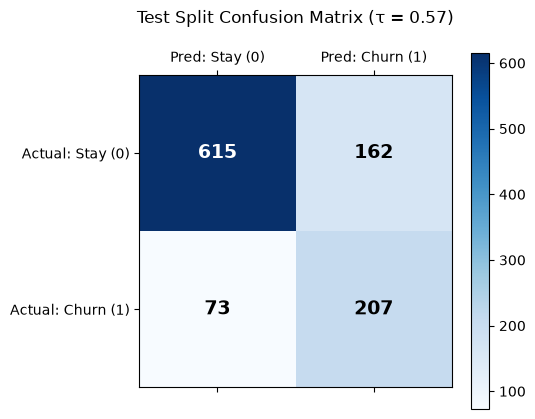

True Negatives (TN): 615 | False Positives (FP): 162
False Negatives (FN): 73 | True Positives (TP): 207 (Churners caught)


In [18]:
# Confusion Matrix Visualization
cm = confusion_matrix(y_test, final_y_pred)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
cax = ax.matshow(cm, cmap='Blues')
fig.colorbar(cax)

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}", ha='center', va='center', color='black' if cm[i,j] < 400 else 'white', fontsize=14, fontweight='bold')

ax.set_xticklabels(['', 'Pred: Stay (0)', 'Pred: Churn (1)'])
ax.set_yticklabels(['', 'Actual: Stay (0)', 'Actual: Churn (1)'])
ax.set_title('Test Split Confusion Matrix (τ = 0.57)', pad=20)
plt.tight_layout()
plt.show()

print(f"True Negatives (TN): {cm[0,0]} | False Positives (FP): {cm[0,1]}")
print(f"False Negatives (FN): {cm[1,0]} | True Positives (TP): {cm[1,1]} (Churners caught)")

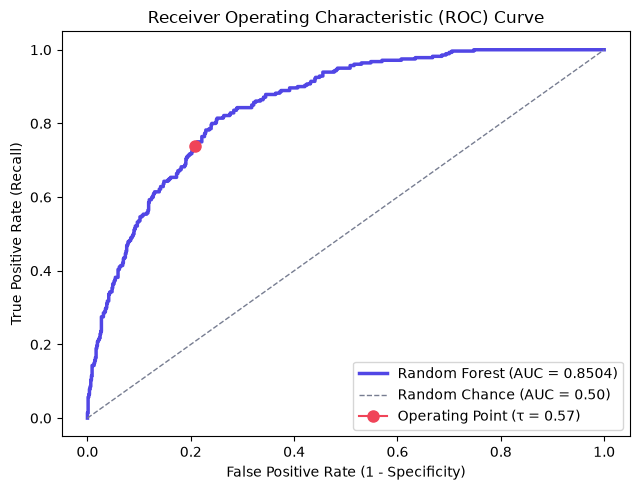

In [19]:
# Receiver Operating Characteristic (ROC) Curve
fpr, tpr, _ = roc_curve(y_test, final_test_proba)
auc_val = roc_auc_score(y_test, final_test_proba)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(fpr, tpr, color='#5146E5', lw=2.5, label=f'Random Forest (AUC = {auc_val:.4f})')
ax.plot([0, 1], [0, 1], color='#777D91', ls='--', lw=1, label='Random Chance (AUC = 0.50)')

opt_fpr = cm[0, 1] / (cm[0, 0] + cm[0, 1])
opt_tpr = cm[1, 1] / (cm[1, 0] + cm[1, 1])
ax.plot(opt_fpr, opt_tpr, marker='o', markersize=8, color='#F04458', label=f'Operating Point (τ = {rf_opt_thresh:.2f})')

ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('Receiver Operating Characteristic (ROC) Curve')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 9. Serialization of Production Artifacts
Save the retrained pipeline into `churn_pipeline.joblib` to power real-time batch predictions in the ChurnPredict SaaS interface.

In [20]:
artifacts_candidates = ["backend/artifacts", "../backend/artifacts"]
artifacts_dir = next((p for p in artifacts_candidates if os.path.exists(p)), "backend/artifacts")
os.makedirs(artifacts_dir, exist_ok=True)

pipeline_path = os.path.join(artifacts_dir, "churn_pipeline.joblib")
joblib.dump(final_pipeline, pipeline_path)
print(f"✓ Production model pipeline saved to: {pipeline_path}")
print(f"✓ Pipeline ready for serving via Django REST Framework & Next.js!")

✓ Production model pipeline saved to: backend/artifacts/churn_pipeline.joblib
✓ Pipeline ready for serving via Django REST Framework & Next.js!
